In [59]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
import re
from collections import Counter


In [2]:
df = pd.read_json("data/hw1_train.jsonl", lines=True)

print("Размер датасета:", df.shape)
print("Названия столбцов:", df.columns.tolist())

display(df.head(3))

Размер датасета: (10000, 5)
Названия столбцов: ['dialog_id', 'language', 'n_user_turns', 'turns', 'labels']


,dialog_id,language,n_user_turns,turns,labels
0,d094012177e,en,7,"[{'role': 'user', 'text': 'it’s like: 1+1=2, b...","{'task_type': 'analysis', 'reaction': 'positiv..."
1,d306fbe61fe,en,8,"[{'role': 'user', 'text': 'Can you help me tra...","{'task_type': 'information_seeking', 'reaction..."
2,dd6905952c7,en,5,"[{'role': 'user', 'text': 'ask questions about...","{'task_type': 'creation', 'reaction': 'neutral..."


In [10]:
negative_df = df[df["labels"].apply(lambda x: isinstance(x, dict) and x.get("reaction") == "negative")]
positive_df = df[df["labels"].apply(lambda x: isinstance(x, dict) and x.get("reaction") == "positive")]
neutral_df = df[df["labels"].apply(lambda x: isinstance(x, dict) and x.get("reaction") == "neutral")]
print("Количество негативных диалогов:", len(negative_df))
print("Количество позитивных диалогов:", len(positive_df))
print("Количество нейтральных диалогов:", len(neutral_df))

Количество негативных диалогов: 923
Количество позитивных диалогов: 303
Количество нейтральных диалогов: 1774


In [11]:
dialog = df.iloc[0]

print("ID:", dialog["dialog_id"])
print("Язык:", dialog["language"])
print("Количество сообщений пользователя:", dialog["n_user_turns"])
print("Метки:", dialog["labels"])

ID: d094012177e
Язык: en
Количество сообщений пользователя: 7
Метки: {'task_type': 'analysis', 'reaction': 'positive', 'user_turns': [{'task_type': 'analysis', 'state': 'continuation', 'reaction': None, 'reaction_reason': None}, {'task_type': 'analysis', 'state': 'continuation', 'reaction': 'neutral', 'reaction_reason': None}, {'task_type': 'open-ended_discovery', 'state': 'continuation', 'reaction': 'positive', 'reaction_reason': 'Humor'}, {'task_type': 'creation', 'state': 'continuation', 'reaction': 'neutral', 'reaction_reason': None}, {'task_type': 'creation', 'state': 'continuation', 'reaction': 'negative', 'reaction_reason': 'Negative_Feedback'}, {'task_type': 'open-ended_discovery', 'state': 'continuation', 'reaction': 'positive', 'reaction_reason': 'Humor'}, {'task_type': 'information_seeking', 'state': 'continuation', 'reaction': 'neutral', 'reaction_reason': None}]}


Преимущественно в датасете английские диалоги, также размечены только 3000 диалогов :(

In [12]:
df["language"].value_counts()

language
en    9929
ru      71
Name: count, dtype: int64

In [13]:
df["n_user_turns"].describe()
# среднее количество реплик у пользователя
# 25% 50% 75% - квартили
# подсчет в количестве сообщений

count    10000.000000
mean         6.698800
std          1.595347
min          5.000000
25%          5.000000
50%          6.000000
75%          8.000000
max         10.000000
Name: n_user_turns, dtype: float64

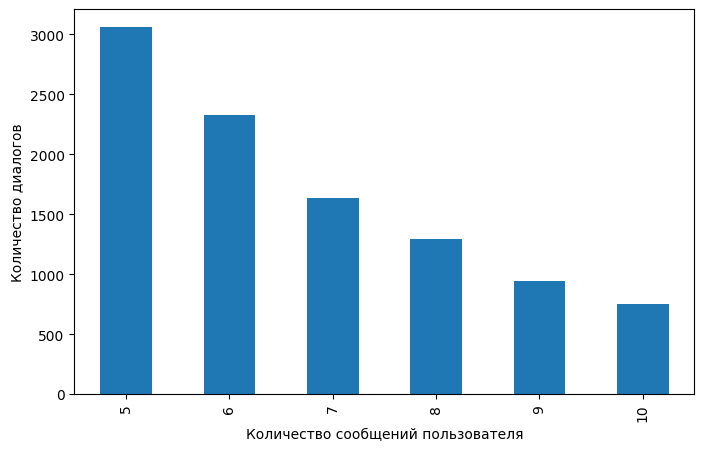

In [16]:
df["n_user_turns"].value_counts().sort_index().plot(kind="bar",figsize=(8, 5))

plt.xlabel("Количество сообщений пользователя")
plt.ylabel("Количество диалогов")
plt.show()

In [18]:
# теперь на длины переписок посмотрим
df["n_turns"] = df["turns"].apply(len)

df["n_turns"].describe()

count    10000.000000
mean        13.397600
std          3.190695
min         10.000000
25%         10.000000
50%         12.000000
75%         16.000000
max         20.000000
Name: n_turns, dtype: float64

In [21]:
(df["n_turns"] == 2 * df["n_user_turns"]).all()
# на каждое соообщение пользователя - 1 ответ модели

np.True_

In [22]:
df["n_chars"] = df["turns"].apply(
    lambda turns: sum(len(turn["text"]) for turn in turns)
)

df["n_chars"].describe()

count    10000.00000
mean     12315.57580
std       8411.34764
min        181.00000
25%       6030.75000
50%      10800.50000
75%      16916.25000
max      59794.00000
Name: n_chars, dtype: float64

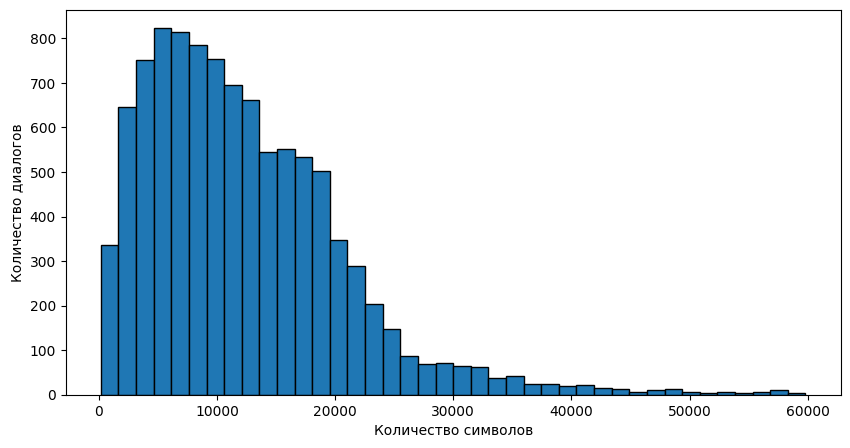

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df["n_chars"], bins=40, edgecolor="black")

plt.xlabel("Количество символов")
plt.ylabel("Количество диалогов")

plt.show()

похоже на хи квадрат

In [24]:
df["user_chars"] = df["turns"].apply(
    lambda turns: sum(
        len(turn["text"])
        for turn in turns
        if turn["role"] == "user"
    )
)

df["assistant_chars"] = df["turns"].apply(
    lambda turns: sum(
        len(turn["text"])
        for turn in turns
        if turn["role"] == "assistant"
    )
)

df[["user_chars", "assistant_chars"]].describe()

,user_chars,assistant_chars
count,10000.000000,10000.000000
mean,2339.589300,9975.986500
std,3819.331032,6758.551704
min,43.000000,18.000000
25%,433.000000,4745.000000
50%,914.000000,8912.000000
75%,2464.500000,14033.500000
max,42987.000000,54682.000000


больше слоВоВ пишет сама модель, а не пользователь - это довольно естественно, среднее поднимают пользовател, которые закидывают тексты

In [40]:
# самые длинные диалоги позырим
df.nlargest(217+1, "user_chars")[
    ["dialog_id", "language", "n_user_turns", "user_chars", "assistant_chars"]
]

,dialog_id,language,n_user_turns,user_chars,assistant_chars
1989,d97c8861e99,en,6,42987,14633
8808,d50f69f92ae,en,9,40714,3646
2423,d7bc62acd10,en,6,40659,15664
8141,d276a7d3769,en,10,39483,4908
688,d5117344965,en,6,39300,18172
...,...,...,...,...,...
8583,dc0040e464a,en,5,13837,15026
7353,dc6671a648b,en,7,13833,15360
4872,db3c976eeb0,en,7,13810,7724
6578,dea0e8d10a0,en,5,13810,3067


In [42]:
# диалог с самым большим объёмом пользовательского текста
dialog = df.loc[1989]

for i, turn in enumerate(dialog["turns"]):
    if turn["role"] == "user":
        print(f"Сообщение №{i + 1}")
        print(f"Длина: {len(turn['text'])} символов")
        print(f"Начало текста: {turn['text'][:300]}")
        print("-" * 60)
# короче, вряд ли это мусор, чел загружал файлы для изучения

Сообщение №1
Длина: 9890 символов
Начало текста: Assume the role of a unity developer 2020.2.6f1 expertise and further expertise in visual studio 2017. I am going to provide you a Unity script in 3 parts, please wait for the full script before responding.
Part 1:
using TMPro;
using UnityEngine;
using UnityEngine.UI;

[RequireComponent(typeof(Audio
------------------------------------------------------------
Сообщение №3
Длина: 10885 символов
Начало текста: Here is part 2 Please wait for part 3
Part 2:
private void GroundCheck()
{
float maxDistance = 0.75f;
if (Physics.Raycast(direction: new Vector3(0f, -1f), origin: raycastTr.position, hitInfo: out var hitInfo, maxDistance: maxDistance))
{
if (hitInfo.transform.tag == “chão”)
{
isGrounded = true;
}
re
------------------------------------------------------------
Сообщение №5
Длина: 9201 символов
Начало текста: After part 3 I will share with you 2 different scripts, please continue to wait.
Here is part 3.
Part 3:
{
colecionavel.SetActiv

In [43]:
empty_messages = 0

for turns in df["turns"]:
    for turn in turns:
        if not turn["text"].strip():
            empty_messages += 1

print("Количество пустых сообщений:", empty_messages)

Количество пустых сообщений: 0


In [46]:
df["dialog_text"] = df["turns"].apply(
    lambda turns: "\n".join(
        turn["role"] + ": " + turn["text"]
        for turn in turns
    )
)

n_duplicates = df["dialog_text"].duplicated().sum()
print("Количество полных дубликатов:", n_duplicates)

Количество полных дубликатов: 0


In [48]:
df["user_text"] = df["turns"].apply(
    lambda turns: "\n".join(
        turn["text"]
        for turn in turns
        if turn["role"] == "user"
    )
)

display(df[["dialog_id", "user_text"]].head(5))

,dialog_id,user_text
0,d094012177e,"it’s like: 1+1=2, but 1+1=2+1+1=? is undefined..."
1,d306fbe61fe,Can you help me train a small language model t...
2,dd6905952c7,ask questions about a fictional voice actor i ...
3,d767a675896,Calculate each prompt based off of data and sh...
4,d7a6280ce8e,"mass spectrometer, the length of AC rod will i..."


In [50]:
vectorizer = TfidfVectorizer(max_features=10000, stop_words="english")

X = vectorizer.fit_transform(df["user_text"])

print("Размер матрицы:", X.shape)

Размер матрицы: (10000, 10000)


In [52]:
knn = NearestNeighbors(n_neighbors=2, metric="cosine", algorithm="brute", n_jobs=-1)
knn.fit(X)

distances, indices = knn.kneighbors(X)

similarities = 1 - distances[:, 1]

print("Максимальное сходство:", similarities.max())
print("Среднее сходство с ближайшим соседом:", similarities.mean())
print("Количество пар-кандидатов со сходством >= 0.95:", (similarities >= 0.95).sum())

Максимальное сходство: 1.0
Среднее сходство с ближайшим соседом: 0.4193032473789733
Количество пар-кандидатов со сходством >= 0.95: 176


In [53]:
pairs = set()

for i in range(len(df)):
    j = indices[i, 1]

    if i != j and similarities[i] >= 0.95:
        pairs.add(tuple(sorted((i, j))))

similar_pairs = pd.DataFrame(
    [
        {
            "index_1": i,
            "index_2": j,
            "similarity": float(X[i].multiply(X[j]).sum())
        }
        for i, j in pairs
    ]
).sort_values("similarity", ascending=False)

print("Количество уникальных пар-кандидатов:", len(similar_pairs))

display(similar_pairs.head(5))

Количество уникальных пар-кандидатов: 95


,index_1,index_2,similarity
80,1085,1752,1.000000
43,2746,8564,1.000000
90,33,9787,1.000000
8,4353,4636,0.999771
29,304,6612,0.998918


In [54]:
i = 1085
j = 1752

print("ПЕРВЫЙ ДИАЛОГ")
print("=" * 70)
print(df.iloc[i]["user_text"][:3000])

print("\nВТОРОЙ ДИАЛОГ")
print("=" * 70)
print(df.iloc[j]["user_text"][:3000])

ПЕРВЫЙ ДИАЛОГ
what’s the content of attack on titan s03e16
what’s the content of attack on titan s04e04
what’s the content of attack on titan s04e05
what’s the content of attack on titan s04e06
动物特工局 电影主要内容
动物特攻队 电影主要内容

ВТОРОЙ ДИАЛОГ
变形金刚5：最后的骑士 主要内容
名侦探柯南：业火的向日葵 主要内容
what’s the content of attack on titan s03e04
what’s the content of attack on titan s03e05
what’s the content of attack on titan s03e06


In [56]:
i = 4353
j = 4636

print("ПЕРВЫЙ ДИАЛОГ")
print(df.iloc[i]["user_text"][:3000])

print("\nВТОРОЙ ДИАЛОГ")
print(df.iloc[j]["user_text"][:3000])

ПЕРВЫЙ ДИАЛОГ
Write an intresting, riveting, lengthy, on-point, descriptive alternate history scenario with plenty of exposition in the form of a written documentary history book chapter, in which the Běiyáng Zhèngfǔ [Beiyang Government |Běiyáng Zhèngfǔ|], a stratocratic [military controlled |stratocratic] authoritarian semi-totalitarian regency that [the Běiyáng Zhèngfǔ] was [what the Běiyáng Zhèngfǔ was] the government [Běiyáng Zhèngfǔ] of [which East Asian regime the Běiyáng Zhèngfǔ was |the Běiyáng Zhèngfǔ| the government |the Běiyáng Zhèngfǔ| of] the Zhōnghuá Mínguó [the Republic of China/Chinese Republic/Republican China |Zhōnghuá Mínguó|] a semi-democratic aristocratic parliamentary presidential republic [the Zhōnghuá Mínguó] that [the Zhōnghuá Mínguó] ruled [the Zhōnghuá Mínguó] over [the East Asian nation the Zhōnghuá Mínguó ruled over]  Zhōngguó [Han China/China |Zhōngguó|, excluding |which Chinese territories are excluded from Zhōngguó| Mòběi Měnggǔ |Outer Mongolia/Mongolia 

In [58]:
def normalize_text(text):
    return re.sub(r"\s+", "", text).lower()

text1 = df.iloc[4353]["user_text"]
text2 = df.iloc[4636]["user_text"]

print("Длины текстов:", len(text1), len(text2))

print(
    "Совпадают после нормализации:",
    normalize_text(text1) == normalize_text(text2)
)

Длины текстов: 34908 35187
Совпадают после нормализации: False


In [60]:
roles = Counter(
    turn["role"]
    for turns in df["turns"]
    for turn in turns
)

print("Роли сообщений:", roles)

print("Уникальные значения reaction:")
print(
    df["labels"].apply(
        lambda x: x.get("reaction") if isinstance(x, dict) else None
    ).value_counts(dropna=False)
)


Роли сообщений: Counter({'user': 66988, 'assistant': 66988})
Уникальные значения reaction:
labels
None        7000
neutral     1774
negative     923
positive     303
Name: count, dtype: int64


In [61]:
def check_roles(turns):
    expected_roles = ["user", "assistant"] * (len(turns) // 2)

    actual_roles = [turn["role"] for turn in turns]

    return actual_roles == expected_roles


print(
    "Диалогов с неправильным порядком ролей:",
    (~df["turns"].apply(check_roles)).sum()
)

Диалогов с неправильным порядком ролей: 0


In [62]:
def get_first_words(turns):
    for turn in turns:
        if turn["role"] == "user":
            words = turn["text"].lower().split()
            return " ".join(words[:8])
    return ""

df["first_words"] = df["turns"].apply(get_first_words)

print("Самые частые начала запросов:")
print(df["first_words"].value_counts().head(15))

Самые частые начала запросов:
first_words
write dialogue from a scene from the animated                                                  14
[response must be written as a short blurb.]                                                   13
create a scam-baiting response to the following email,                                          8
come up with a better sentence for clarity,                                                     7
write me a story about the wordgirl villains                                                    5
using system.collections; using system.collections.generic; using unityengine; public class     5
import gradio as gr import mysql.connector from mysql.connector                                 5
below is a paragraph from an academic paper.                                                    5
write a comprehensive astrological interpretation of the asteroid                               5
give all subject, relation, and object triplets from                        

In [63]:
df["reaction"] = df["labels"].apply(
    lambda x: x.get("reaction") if isinstance(x, dict) else None
)
pairs_with_labels = similar_pairs.copy()

pairs_with_labels["reaction_1"] = pairs_with_labels["index_1"].apply(
    lambda i: df.iloc[i]["reaction"]
)

pairs_with_labels["reaction_2"] = pairs_with_labels["index_2"].apply(
    lambda i: df.iloc[i]["reaction"]
)

labeled_pairs = pairs_with_labels.dropna(
    subset=["reaction_1", "reaction_2"]
)

print("Пар, где оба диалога размечены:", len(labeled_pairs))

print(
    "Пар с различающимися реакциями:",
    (labeled_pairs["reaction_1"] != labeled_pairs["reaction_2"]).sum()
)

Пар, где оба диалога размечены: 13
Пар с различающимися реакциями: 6


### Согласованность меток реакции

Для проверки согласованности разметки были рассмотрены ранее найденные пары диалогов с косинусным сходством пользовательских сообщений не менее 0,95.

Среди найденных пар 13 имели метки реакции у обоих диалогов. В 6 случаях метки различались.

Это не обязательно свидетельствует об ошибках разметки, поскольку сравнение проводилось только по пользовательским сообщениям, а ответы ассистента могли отличаться.

Таким образом, автоматическое удаление похожих диалогов или изменение их меток не производится.

## Подытожим 

Дисбаланс классов: положительных реакций значительно меньше нейтральных. Это важно для обучения и выбора метрики.



Языки: 9929 диалогов на английском и 71 на русском, согласно полю language.



Длина: в каждом диалоге от 5 до 10 сообщений пользователя, среднее — около 6,7.



Объём текста: средняя длина диалога — около 12 316 символов, причём примерно 81% текста приходится на ассистента.



Качество данных: пустых сообщений и точных дубликатов нет, роли чередуются правильно.



Почти дубликаты: у 176 диалогов сходство с ближайшим соседом по TF-IDF не ниже 0,95. Некоторые являются похожими шаблонами, но содержательно различаются.



Согласованность разметки: среди 13 найденных пар похожих размеченных диалогов у 6 различаются реакции. Это не обязательно ошибка, поскольку ответы ассистента тоже могут различаться.